# Projection: tcc & tprate

### Why this notebook matters

This notebook demonstrates optical-flow-based feature tracking of cloud cover and precipitation in hourly high-resolution projection output, with monthly aggregation and GIF/HTML animation.

**Purpose** - Track cloud cover and precipitation features in high-resolution hourly projection output, including optical-flow-based feature tracking, monthly-mean computation, and GIF/HTML animation generation.

**Required input data** - Hourly `tcc` and `tprate` GRIB files on the HEALPix grid under `{PROJ2559_DIR}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - Monthly means, animation frames, and feature-tracking visualisations.

## Key techniques demonstrated

- Optical-flow feature tracking (scikit-image)
- GIF/HTML animation generation
- Interactive widgets (ipywidgets)
- Dask-backed hourly-data processing
- tqdm progress tracking

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set this path to your own data copy before running:
#
# PROJ2559_DIR : root of the projection experiment (2020-2039)
#                (subfolders: sfc_hr/tco2559_proj/ for hourly GRIB output)

PROJ2559_DIR = "/path/to/proj2559"  # <-- EDIT before running

## Installation & loading packages

In [ ]:
pip install healpy

In [ ]:
import sys
print(sys.version)
import healpy
print(healpy.__version__)

In [ ]:
import sys
print(sys.executable)

In [ ]:
import os
import numpy as np
import numpy as np
import xarray as xr
import healpy as hp
import eccodes

import matplotlib.cm as cm
import matplotlib.pyplot as plt

import dask.array as da

import cartopy.crs as ccrs
import cartopy.feature as cfeature

import cmocean

In [ ]:
import healpy
print(healpy.__version__)

## sfc variables: tprate

### Check 'one year' data

In [ ]:
# @ Levante
pathsfc_2t = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tprate_healpix_hourly_2025.grb"
data_sfc_tprate = xr.open_dataset(pathsfc_2t, engine="cfgrib")
data_sfc_tprate

In [ ]:
# Load the model data
pathsfc_2t = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tprate_healpix_hourly_2025.grb"
data_sfc_tprate = xr.open_dataset(pathsfc_2t, engine="cfgrib")

# Extract precipitation data
tp = data_sfc_tprate['tprate']

# # Convert precipitation from m/s to mm/day
# tp = tp * 86400000  # 1 m/s = 86400000 mm/day

# Convert precipitation from kg mÃƒÆ’Ã‚Â¢Ãƒâ€šÃ‚ÂÃƒâ€šÃ‚Â»ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â² sÃƒÆ’Ã‚Â¢Ãƒâ€šÃ‚ÂÃƒâ€šÃ‚Â»ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â¹ to mm/day
tp = tp * 86.4  # Conversion factor

In [ ]:
# Calculate and Plot : Cartesian view 

# Calculate the annual mean (climatology for 2025)
tp_clim = tp.mean(dim='time')

# Convert the xarray DataArray to a numpy array
trend_healpix_map = tp_clim.values

# Plot the Trend Map Using healpy.cartview
plt.figure(figsize=(12, 8))

# Plot the trend map using Healpy's cartview
hp.cartview(
    trend_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Annual Mean Precipitation (2025)",
    min=None,            # Minimum value for the color scale (auto if None)
    max=None,            # Maximum value for the color scale (auto if None)
    cmap=cmocean.cm.rain,      # Colormap (use a precipitation-friendly colormap)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Precipitation (mm/day)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

#### Robinson projection

In [ ]:
# Interpolate the data

# Check the HEALPix data
print(f"HEALPix data min: {np.nanmin(trend_healpix_map)}, max: {np.nanmax(trend_healpix_map)}")
print(f"HEALPix data shape: {trend_healpix_map.shape}")

# Replace NaN values in the HEALPix data
trend_healpix_map = np.nan_to_num(trend_healpix_map, nan=0)

# Create a regular latitude/longitude grid
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

# Initialize the interpolated grid
grid_trend = np.zeros_like(grid_lat)

# Perform interpolation
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        lon = grid_lon[i, j]
        lat = grid_lat[i, j]
        
        # Ensure longitude is in the range [-180, 180]
        if lon > 180:
            lon -= 360
        
        # Interpolate the HEALPix data
        grid_trend[i, j] = hp.get_interp_val(trend_healpix_map, lon, lat, lonlat=True, nest=True)

# Replace NaN values in the interpolated data
grid_trend = np.nan_to_num(grid_trend, nan=0)

# Check the interpolated data
print(f"Interpolated precipitation values min: {np.nanmin(grid_trend)}, max: {np.nanmax(grid_trend)}")
print(f"Interpolated data shape: {grid_trend.shape}")

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import numpy as np

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Define levels for the colormap based on the actual data range
levels = np.linspace(0, 0.03379736721868453, 21)  # Adjust based on your data range

# Use the cmo.rain colormap
cmap = cmo.rain

# Plot the precipitation map
precip_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,  # Use the actual data (not normalized)
    transform=ccrs.PlateCarree(),
    cmap=cmap,  # Use the colormap
    levels=levels,  # Set levels to match the actual data range
    extend="both",  # Extend the colorbar to include values outside the range
)

# Add coastlines
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add gridlines
ax.gridlines()

# Add a colorbar (customized placement and style)
cbar_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(precip_plot, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Precipitation (mm/day)", fontsize=12)

# Add a title
plt.title("Annual Mean Precipitation (2025)", fontsize=14, pad=20)

# Show the plot
plt.show()

### Years: 2020 - 2039

In [ ]:
import os
import xarray as xr

# Define the base path and years
base_path = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tprate_healpix_hourly_"
years = range(2030, 2031)  # From 2020 to 2039
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_tpr/"  # Directory to save monthly means

In [ ]:
# @ Levante
pathsfc_2t = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tprate_healpix_hourly_2023.grb"
data_sfc_tprate = xr.open_dataset(pathsfc_2t, engine="cfgrib")
data_sfc_tprate

In [ ]:
# ## Create Monthly means

# # # Loop through each year
# for year in years:
#     # Construct the file path
#     file_path = f"{base_path}{year}.grb"
    
#     # Load the dataset with Dask for parallel processing
#     data = xr.open_dataset(file_path, engine="cfgrib", chunks={"time": 1000})  # Chunk time dimension for Dask
    
#     # Extract the variable of interest (tprate)
#     tprate = data["tprate"]  # Total precipitation
    
#     # Group by month and compute the monthly mean
#     monthly_means = tprate.groupby("time.month").mean(dim="time").compute()  # Compute the result using Dask
    
#     # Save the monthly means to a NetCDF file
#     output_file = f"{output_dir}monthly_mean_tprate_{year}.nc"
#     monthly_means.to_dataset(name="tprate").to_netcdf(output_file)
    
#     # Close the dataset to free up memory
#     data.close()

# print("Monthly mean maps saved successfully.")

In [ ]:
# Define the output directory where monthly mean files are stored
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_tpr/"

# List of monthly mean files
monthly_files = [f"{output_dir}monthly_mean_tpr_{year}.nc" for year in range(2020, 2040)]

In [ ]:
import xarray as xr
import pandas as pd

# Function to add time coordinates to a dataset
def add_time_coords(ds, year):
    # Create a time coordinate for each month
    time = pd.date_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=time)
    return ds

# Load one monthly mean file to inspect
sample_file = f"{output_dir}monthly_mean_tprate_2020.nc"
ds_sample = xr.open_dataset(sample_file)

# Add time coordinates to the dataset
ds_sample = add_time_coords(ds_sample, 2020)

# Print the updated dataset
print(ds_sample)

In [ ]:
# Loop through each year and add time coordinates
datasets = []
for year in range(2020, 2040):
    file_path = f"{output_dir}monthly_mean_tprate_{year}.nc"
    ds = xr.open_dataset(file_path)
    ds = add_time_coords(ds, year)
    datasets.append(ds)

# Concatenate all datasets along the time dimension
ds = xr.concat(datasets, dim="time")

# Print the concatenated dataset
print(ds)

In [ ]:
# Group by year and compute the annual mean
annual_means = ds["tprate"].groupby("time.year").mean(dim="time")

# Print the annual means
print("Annual means:")
print(annual_means)

print(annual_means.shape)

In [ ]:
# Compute the long-term mean across all years
long_term_mean = annual_means.mean(dim="year")

# Print the long-term mean
print("Long-term mean precipitation rate:")
print(long_term_mean)

print(long_term_mean.shape)

In [ ]:
# Compute the long-term mean across all months 
long_term_mean = ds["tprate"].mean(dim=["time", "month"])

# Print the long-term mean
print("Long-term mean precipitation rate:")
print(long_term_mean)

print(long_term_mean.shape)

In [ ]:
## Define and Interpolate grid

# Define the target grid (180x360)
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

# Initialize the interpolated grid
grid_trend = np.zeros_like(grid_lat)

# Perform interpolation
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        lon = grid_lon[i, j]
        lat = grid_lat[i, j]
        
        # Ensure longitude is in the range [-180, 180]
        if lon > 180:
            lon -= 360
        
        # Interpolate the HEALPix data
        grid_trend[i, j] = hp.get_interp_val(long_term_mean.values, lon, lat, lonlat=True, nest=True)

# Replace NaN values in the interpolated data
grid_trend = np.nan_to_num(grid_trend, nan=0)

# Check the interpolated data
print(f"Interpolated precipitation rate values min: {np.nanmin(grid_trend)}, max: {np.nanmax(grid_trend)}")
print(f"Interpolated data shape: {grid_trend.shape}")

In [ ]:
# Convert precipitation rate from kg mÃƒÆ’Ã‚Â¢Ãƒâ€šÃ‚ÂÃƒâ€šÃ‚Â»ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â² sÃƒÆ’Ã‚Â¢Ãƒâ€šÃ‚ÂÃƒâ€šÃ‚Â»ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â¹ to mm/day
grid_trend_mm_day = grid_trend * 86400

# Print the range of the converted data
print(f"Interpolated precipitation rate (mm/day) min: {np.nanmin(grid_trend_mm_day)}, max: {np.nanmax(grid_trend_mm_day)}")

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Define levels for the colormap based on the actual data range
# Adjust levels based on your data range (min and max in mm/day)
levels = np.linspace(0, 20, 21)  # Example: 21 levels from 0 to 30 mm/day

# Use a colormap suitable for precipitation (e.g., "rain" from cmocean)
cmap = cmo.rain  # Precipitation-friendly colormap

# Plot the precipitation rate map
precip_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend_mm_day,  # Use the converted data
    transform=ccrs.PlateCarree(),
    cmap=cmap,  # Use the colormap
    levels=levels,  # Set levels to match the data range
    extend="both",  # Extend the colorbar to include values outside the range
)

# Add coastlines
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add gridlines
ax.gridlines()

# Add a colorbar (customized placement and style)
cbar_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(precip_plot, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Precipitation Rate (mm/day)", fontsize=12)  # Update the label

# Add a title
plt.title("Long-Term Mean Precipitation Rate (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)", fontsize=14, pad=20)

# Show the plot
plt.show()

## sfc variables: tcc

### Check one Year

In [ ]:
# Load the model data
pathsfc_2t = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tcc_healpix_hourly_2025.grb"
data_sfc_tcc = xr.open_dataset(pathsfc_2t, engine="cfgrib")

# Extract precipitation data
tc = data_sfc_tcc['tcc']

In [ ]:
data_sfc_tcc

#### Cartesian

In [ ]:
# Calculate and Plot : Cartesian view 

# Calculate the annual mean (climatology for 2025)
tp_clim = tc.mean(dim='time')

# Convert the xarray DataArray to a numpy array
trend_healpix_map = tp_clim.values

In [ ]:
# Plot the Trend Map Using healpy.cartview
plt.figure(figsize=(12, 8))

# Plot the trend map using Healpy's cartview
hp.cartview(
    trend_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Annual Mean Precipitation (2025)",
    min=None,            # Minimum value for the color scale (auto if None)
    max=None,            # Maximum value for the color scale (auto if None)
    cmap=plt.cm.Greys,      # Colormap (use a precipitation-friendly colormap)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Cloud cover", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

#### Robinson

In [ ]:
# Plot Robinson

import numpy as np

# Check the HEALPix data
print(f"HEALPix data min: {np.nanmin(trend_healpix_map)}, max: {np.nanmax(trend_healpix_map)}")
print(f"HEALPix data shape: {trend_healpix_map.shape}")

# Replace NaN values in the HEALPix data
trend_healpix_map = np.nan_to_num(trend_healpix_map, nan=0)

In [ ]:
# Create a regular latitude/longitude grid
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

In [ ]:
import healpy as hp

# Initialize the interpolated grid
grid_trend = np.zeros_like(grid_lat)

# Perform interpolation
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        lon = grid_lon[i, j]
        lat = grid_lat[i, j]
        
        # Ensure longitude is in the range [-180, 180]
        if lon > 180:
            lon -= 360
        
        # Interpolate the HEALPix data
        grid_trend[i, j] = hp.get_interp_val(trend_healpix_map, lon, lat, lonlat=True, nest=True)

# Replace NaN values in the interpolated data
grid_trend = np.nan_to_num(grid_trend, nan=0)

# Check the interpolated data
print(f"Interpolated cloud cover values min: {np.nanmin(grid_trend)}, max: {np.nanmax(grid_trend)}")
print(f"Interpolated data shape: {grid_trend.shape}")

In [ ]:
# Plotting

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Define levels for the colormap based on the actual data range
levels = np.linspace(0, 1, 21)  # Cloud cover ranges from 0 to 1 (0% to 100%)

# Use a colormap suitable for cloud cover (e.g., grayscale or blue-to-white)
cmap = plt.cm.Greys  # Black-to-white colormap
# OR
# cmap = cmocean.cm.ice  # Blue-to-white colormap

# Plot the cloud cover map
cloud_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,  # Use the interpolated data
    transform=ccrs.PlateCarree(),
    cmap=cmap,  # Use the colormap
    levels=levels,  # Set levels to match the data range
    extend="both",  # Extend the colorbar to include values outside the range
)

# Add coastlines
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add gridlines
ax.gridlines()

# Add a colorbar (customized placement and style)
cbar_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(cloud_plot, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Cloud Cover (%)", fontsize=12)

# Add a title
plt.title("Annual Mean Cloud Cover (2025)", fontsize=14, pad=20)

# Show the plot
plt.show()

### Years: 2020 - 2039

In [ ]:
import os
import xarray as xr

# Define the base path and years
base_path = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tcc_healpix_hourly_"
years = range(2020, 2040)  # From 2020 to 2039
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_tcc/"  # Directory to save monthly means

In [ ]:
### Create Monthly means

# # Loop through each year
# for year in years:
#     # Construct the file path
#     file_path = f"{base_path}{year}.grb"
    
#     # Load the dataset with Dask for parallel processing
#     data = xr.open_dataset(file_path, engine="cfgrib", chunks={"time": 1000})  # Chunk time dimension for Dask
    
#     # Extract the variable of interest (tcc)
#     tcc = data["tcc"]  # Total cloud cover
    
#     # Group by month and compute the monthly mean
#     monthly_means = tcc.groupby("time.month").mean(dim="time").compute()  # Compute the result using Dask
    
#     # Save the monthly means to a NetCDF file
#     output_file = f"{output_dir}monthly_mean_tcc_{year}.nc"
#     monthly_means.to_dataset(name="tcc").to_netcdf(output_file)
    
#     # Close the dataset to free up memory
#     data.close()

# print("Monthly mean maps saved successfully.")

In [ ]:
# Define the output directory where monthly mean files are stored
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_tcc/"

# List of monthly mean files
monthly_files = [f"{output_dir}monthly_mean_tcc_{year}.nc" for year in range(2020, 2040)]

In [ ]:
import xarray as xr
import pandas as pd

# Function to add time coordinates to a dataset
def add_time_coords(ds, year):
    # Create a time coordinate for each month
    time = pd.date_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=time)
    return ds

# Load one monthly mean file to inspect
sample_file = f"{output_dir}monthly_mean_tcc_2020.nc"
ds_sample = xr.open_dataset(sample_file)

# Add time coordinates to the dataset
ds_sample = add_time_coords(ds_sample, 2020)

# Print the updated dataset
print(ds_sample)

In [ ]:
# Loop through each year and add time coordinates
datasets = []
for year in range(2020, 2040):
    file_path = f"{output_dir}monthly_mean_tcc_{year}.nc"
    ds = xr.open_dataset(file_path)
    ds = add_time_coords(ds, year)
    datasets.append(ds)

# Concatenate all datasets along the time dimension
ds = xr.concat(datasets, dim="time")

# Print the concatenated dataset
print(ds)

In [ ]:
# Group by year and compute the annual mean
annual_means = ds["tcc"].groupby("time.year").mean(dim="time")

# Print the annual means
print("Annual means:")
print(annual_means)

print(annual_means.shape)

In [ ]:
# Compute the long-term mean across all years
long_term_mean = annual_means.mean(dim="year")

# Print the long-term mean
print("Long-term mean cloud cover:")
print(long_term_mean)

print(long_term_mean.shape)

In [ ]:
# Compute the long-term mean across all years and months
long_term_mean = ds["tcc"].mean(dim=["time", "month"])

# Print the long-term mean
print("Long-term mean cloud cover:")
print(long_term_mean)

print(long_term_mean.shape)

In [ ]:
import healpy as hp
import matplotlib.pyplot as plt

# Compute the long-term mean across all years and months
long_term_mean = ds["tcc"].mean(dim=["time", "month"])

# Plot the long-term mean using healpy.cartview
hp.cartview(
    long_term_mean.values,  # HEALPix data
    nest=True,              # Use NESTED ordering
    title="Long-Term Mean Cloud Cover (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)",
    min=0,                  # Minimum value for the color scale
    max=1,                  # Maximum value for the color scale
    cmap="Blues",           # Colormap for cloud cover
    badcolor="gray",        # Color for invalid/missing data
    hold=True,              # Hold the plot for further customization
)

# Add latitude and longitude labels
hp.graticule()

# Show the plot
plt.show()

In [ ]:
print(long_term_mean.shape)

In [ ]:
import numpy as np

# Define the target grid (180x360)
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

In [ ]:
import healpy as hp

# Initialize the interpolated grid
grid_trend = np.zeros_like(grid_lat)

# Perform interpolation
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        lon = grid_lon[i, j]
        lat = grid_lat[i, j]
        
        # Ensure longitude is in the range [-180, 180]
        if lon > 180:
            lon -= 360
        
        # Interpolate the HEALPix data
        grid_trend[i, j] = hp.get_interp_val(long_term_mean.values, lon, lat, lonlat=True, nest=True)

# Replace NaN values in the interpolated data
grid_trend = np.nan_to_num(grid_trend, nan=0)

# Check the interpolated data
print(f"Interpolated cloud cover values min: {np.nanmin(grid_trend)}, max: {np.nanmax(grid_trend)}")
print(f"Interpolated data shape: {grid_trend.shape}")

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Define levels for the colormap based on the actual data range
levels = np.linspace(0, 1, 21)  # Cloud cover ranges from 0 to 1 (0% to 100%)

# Use a colormap suitable for cloud cover (e.g., grayscale or blue-to-white)
cmap = plt.cm.Greys  # Black-to-white colormap
# OR
# cmap = cmocean.cm.ice  # Blue-to-white colormap

# Plot the cloud cover map
cloud_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,  # Use the interpolated data
    transform=ccrs.PlateCarree(),
    cmap="Blues",  # Use the colormap
    levels=levels,  # Set levels to match the data range
    extend="both",  # Extend the colorbar to include values outside the range
)

# Add coastlines
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add gridlines
ax.gridlines()

# Add a colorbar (customized placement and style)
cbar_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(cloud_plot, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Cloud Cover (%)", fontsize=12)

# Add a title
plt.title("Long-Term Mean Cloud Cover (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)", fontsize=14, pad=20)

# Show the plot
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Define levels for the colormap based on the actual data range
levels = np.linspace(0, 1, 21)  # Cloud cover ranges from 0 to 1 (0% to 100%)

# Use a colormap suitable for cloud cover (e.g., grayscale or blue-to-white)
cmap = plt.cm.Greys  # Black-to-white colormap
# OR
# cmap = cmocean.cm.ice  # Blue-to-white colormap

# Plot the cloud cover map
cloud_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,  # Use the interpolated data
    transform=ccrs.PlateCarree(),
    cmap=cmap,  # Use the colormap
    levels=levels,  # Set levels to match the data range
    extend="both",  # Extend the colorbar to include values outside the range
)

# Add coastlines
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add gridlines
ax.gridlines()

# Add a colorbar (customized placement and style)
cbar_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(cloud_plot, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Cloud Cover (%)", fontsize=12)

# Add a title
plt.title("Long-Term Mean Cloud Cover (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)", fontsize=14, pad=20)

# Show the plot
plt.show()

# Check Cloud cover:cyclone

In [ ]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import healpy as hp
import eccodes
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import dask.array as da
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

In [ ]:
# Load the model data
pathsfc_2t = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tcc_healpix_hourly_2024.grb"
data_sfc_tcc = xr.open_dataset(pathsfc_2t, engine="cfgrib")

# Extract precipitation data
tc = data_sfc_tcc['tcc']

In [ ]:
print(tc)
print(data_sfc_tcc)

### Robinson plot

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import healpy as hp
import pandas as pd

# 1. First create a regular grid for interpolation
def create_grid(resolution=1.0):
    """Create a regular lat/lon grid for interpolation"""
    lats = np.arange(-90, 90 + resolution, resolution)
    lons = np.arange(-180, 180 + resolution, resolution)
    grid_lon, grid_lat = np.meshgrid(lons, lats)
    return grid_lon, grid_lat

# 2. Function to interpolate HEALPix data to regular grid
def healpix_to_grid(healpix_data, grid_lon, grid_lat, nest=True):
    """Interpolate HEALPix data to regular lat/lon grid"""
    grid_data = np.zeros_like(grid_lat)
    
    for i in range(grid_lat.shape[0]):
        for j in range(grid_lat.shape[1]):
            lon = grid_lon[i, j]
            lat = grid_lat[i, j]
            grid_data[i, j] = hp.get_interp_val(healpix_data, lon, lat, lonlat=True, nest=nest)
    
    return np.nan_to_num(grid_data, nan=0)

# 3. Function to plot cloud cover
def plot_cloud_cover(grid_lon, grid_lat, grid_data, time, cmap=plt.cm.Greys):
    """Plot cloud cover data on a global map"""
    fig = plt.figure(figsize=(15, 8))
    ax = plt.axes(projection=ccrs.Robinson())
    
    # Define levels for cloud cover (0-1 scale)
    levels = np.linspace(0, 1, 21)
    
    # Plot the data
    plot = ax.contourf(
        grid_lon, grid_lat, grid_data,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        levels=levels,
        extend='both'
    )
    
    # Add map features
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
    ax.gridlines(linestyle='--', alpha=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(plot, orientation='horizontal', pad=0.05, aspect=50, shrink=0.8)
    cbar.set_label('Cloud Cover Fraction (0-1)', fontsize=12)
    
    # Add title
    plt.title(f'Global Cloud Cover - {time.strftime("%Y-%m-%d %H:%M UTC")}', fontsize=14, pad=20)
    
    plt.tight_layout()
    plt.show()



In [ ]:
# 4. Main processing
# Create the interpolation grid
grid_lon, grid_lat = create_grid(resolution=1.0)  # 1-degree resolution

# Select time range (Oct 4-7, 2024) at 12-hour intervals
selected_times = pd.date_range(start='2024-10-04', end='2024-10-05', freq='12H')[:-1]

# Process and plot each timestep
for time in selected_times:
    # Get HEALPix data for this timestep
    cloud_data = tc.sel(time=np.datetime64(time)).values
    
    # Interpolate to regular grid
    grid_data = healpix_to_grid(cloud_data, grid_lon, grid_lat, nest=True)
    
    # Plot the data
    plot_cloud_cover(grid_lon, grid_lat, grid_data, time, cmap=plt.cm.Blues)

### Animation: Each time step

In [ ]:
# Part 1: Data Processing (Run this cell first)
import numpy as np
import healpy as hp
import pandas as pd
import xarray as xr
from tqdm.notebook import tqdm

# Load the data
path = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_tcc_healpix_hourly_2024.grb"
tc = xr.open_dataset(path, engine="cfgrib")['tcc']

# Select Oct 4-7 at 12-hour intervals
selected_times = pd.date_range('2024-10-03', '2024-10-14', freq='2H')
tc_oct = tc.sel(time=selected_times)

# Create 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° grid
lons, lats = np.meshgrid(np.arange(-180, 181), np.arange(-90, 91))
grid_data = np.zeros((len(selected_times), lats.shape[0], lons.shape[1]))

# Vectorized interpolation
print("Processing data...")
for i, t in enumerate(tqdm(selected_times)):
    healpix_data = tc.sel(time=t).values
    # Flatten grid and interpolate all points at once
    pts = np.column_stack([lons.ravel(), lats.ravel()])
    pts[:, 0] = np.where(pts[:, 0] > 180, pts[:, 0] - 360, pts[:, 0])  # Fix longitude
    grid_data[i] = hp.get_interp_val(healpix_data, pts[:, 0], pts[:, 1], lonlat=True, nest=True).reshape(lats.shape)

# Replace NaNs with 0
grid_data = np.nan_to_num(grid_data)
print("Data processing complete!")

In [ ]:
# Part 2: Visualization (Run this after processing)
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from ipywidgets import interact, Dropdown

# Set up the figure
def plot_cloud_cover(time_idx=0):
    fig = plt.figure(figsize=(15, 8))
    ax = fig.add_subplot(111, projection=ccrs.Robinson())
    
    # Plot data
    im = ax.pcolormesh(lons, lats, grid_data[time_idx], 
                      transform=ccrs.PlateCarree(),
                      cmap=plt.cm.Greys, vmin=0, vmax=1)
    
    # Add map features
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.3)
    ax.gridlines(linestyle='--', alpha=0.5)
    
    # Colorbar
    cbar = plt.colorbar(im, orientation='horizontal', pad=0.05, aspect=50)
    cbar.set_label('Cloud Cover Fraction (0-1)')
    
    # Title
    plt.title(f'Global Cloud Cover - {selected_times[time_idx].strftime("%Y-%m-%d %H:%M UTC")}',
              fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()

# Create interactive widget
time_options = [(t.strftime('%Y-%m-%d %H:%M'), i) for i, t in enumerate(selected_times)]
interact(plot_cloud_cover, 
         time_idx=Dropdown(options=time_options, description='Select Time'))

### Animation

In [ ]:
# Simple Cloud Cover Animation (No FFmpeg needed)
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Set up the figure
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(111, projection=ccrs.Robinson())
ax.set_global()

# Initial empty plot
im = ax.pcolormesh(lons, lats, grid_data[0],
                 transform=ccrs.PlateCarree(),
                 cmap=plt.cm.Blues,
                 vmin=0, vmax=1)

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(linestyle='--', alpha=0.5)

# Add colorbar
cbar = fig.colorbar(im, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label('Cloud Cover (0-1)')

# Title with timestamp
title = ax.set_title('', fontsize=12, pad=10)

# Animation update function
def update(frame):
    im.set_array(grid_data[frame].ravel())
    title.set_text(f'Global Cloud Cover - {selected_times[frame].strftime("%Y-%m-%d %H:%M")}')
    return im, title

# Create JavaScript animation
ani = FuncAnimation(
    fig, 
    update, 
    frames=len(selected_times),
    interval=200,  # 200ms between frames
    blit=False
)

# Display in notebook
plt.close(fig)  # Prevents double display
HTML(ani.to_jshtml())  # Uses JavaScript instead of video

In [ ]:
# Enhanced Cloud Cover Animation with Beautiful Basemap
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Set up the figure with better colors
fig = plt.figure(figsize=(14, 8))
ax = fig.add_subplot(111, projection=ccrs.Robinson(central_longitude=180))
ax.set_global()

# Add beautiful basemap features
ax.add_feature(cfeature.LAND, facecolor='#e0d8b0')  # Sandy land color
ax.add_feature(cfeature.OCEAN, facecolor='#9ecae1')  # Light blue ocean
ax.add_feature(cfeature.LAKES, facecolor='#9ecae1', alpha=0.5)
ax.add_feature(cfeature.RIVERS, edgecolor='#9ecae1', linewidth=0.5)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='#333333')
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5, edgecolor='#333333')

# Plot cloud cover with semi-transparency
im = ax.pcolormesh(lons, lats, grid_data[0],
                  transform=ccrs.PlateCarree(),
                  cmap=plt.cm.Blues_r,  # _r reverses the colormap (white clouds on blue)
                  vmin=0, vmax=1,
                  alpha=0.7)  # Makes clouds slightly transparent

# Add colorbar with better styling
cbar = plt.colorbar(im, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label('Cloud Cover Fraction (0-1)', fontsize=10)
cbar.outline.set_edgecolor('#333333')

# Title with better styling
title = ax.set_title(f'Global Cloud Cover - {selected_times[0].strftime("%Y-%m-%d %H:%M UTC")}',
                   fontsize=12, pad=10, color='#333333')

# Animation update function
def update(frame):
    im.set_array(grid_data[frame].ravel())
    title.set_text(f'Global Cloud Cover - {selected_times[frame].strftime("%Y-%m-%d %H:%M UTC")}')
    return im, title

# Add elevation colors (optional)
ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m',
              edgecolor='none', facecolor='#d9d9d9'), zorder=0)
ax.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m',
              edgecolor='none', facecolor='#c6dbef'), zorder=0)

# Create animation
ani = FuncAnimation(fig, update, frames=len(selected_times), interval=200, blit=False)
plt.close(fig)

# Display in notebook
HTML(ani.to_jshtml())

### Hurricane Milton

In [ ]:
# Hurricane Milton Analysis Setup
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime, timedelta

# 1. Define the hurricane tracking parameters (adjust these as needed)
milton_path = {
    'start_date': datetime(2024, 10, 8),  # Example start date
    'end_date': datetime(2024, 10, 12),   # Example end date
    'zoom_box': [-100, -70, 15, 35]  # [lon_min, lon_max, lat_min, lat_max] (Gulf of Mexico)
}

# 2. Filter data for Milton's period
milton_tc = tc.sel(time=slice(milton_path['start_date'], milton_path['end_date']))

# 3. Create analysis function
def plot_hurricane_frame(time_idx, zoom=False):
    """Plot cloud cover for hurricane analysis"""
    time = milton_tc.time[time_idx].values
    cloud_data = milton_tc.isel(time=time_idx).values
    
    # Create figure
    fig = plt.figure(figsize=(12, 8))
    
    # Set projection based on zoom
    if zoom:
        ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
        ax.set_extent(milton_path['zoom_box'], crs=ccrs.PlateCarree())
        title_suffix = " (Zoomed)"
    else:
        ax = fig.add_subplot(111, projection=ccrs.Robinson(central_longitude=-90))
        ax.set_global()
        title_suffix = ""
    
    # Plot cloud cover with enhanced contrast
    im = ax.pcolormesh(lons, lats, 
                      healpix_to_grid(cloud_data, lons, lats),
                      transform=ccrs.PlateCarree(),
                      cmap=plt.cm.Blues,
                      vmin=0.3,  # Higher threshold for better visibility
                      vmax=1,
                      alpha=0.8)
    
    # Add critical map features
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
    ax.add_feature(cfeature.STATES, linestyle=':', linewidth=0.3)
    ax.add_feature(cfeature.LAND, facecolor='#f0f0f0', zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor='#a0c8f0', zorder=0)
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title with timestamp
    plt.title(f"Hurricane Milton Cloud Cover\n{pd.to_datetime(time).strftime('%Y-%m-%d %H:%M UTC')}{title_suffix}",
             fontsize=14, pad=20)
    
    # Add colorbar
    cbar = plt.colorbar(im, orientation='horizontal', pad=0.05, shrink=0.7)
    cbar.set_label('Cloud Cover Density (0-1)')
    
    plt.tight_layout()
    plt.show()

# 4. Create interactive analysis
from ipywidgets import interact, IntSlider, ToggleButtons

interact(plot_hurricane_frame,
         time_idx=IntSlider(min=0, max=len(milton_tc.time)-1, step=1, description='Time Step'),
         zoom=ToggleButtons(options=[('Global View', False), ('Zoomed', True)],
                          description='View Mode'))

In [ ]:
# Global View Animation
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Set up global figure
fig_global = plt.figure(figsize=(14, 7))
ax_global = fig_global.add_subplot(111, projection=ccrs.Robinson(central_longitude=180))
ax_global.set_global()

# Base map features
ax_global.add_feature(cfeature.LAND, facecolor='#f5f5dc', zorder=0)
ax_global.add_feature(cfeature.OCEAN, facecolor='#add8e6', zorder=0)
ax_global.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=1)

# Initial cloud plot
im_global = ax_global.pcolormesh(lons, lats, grid_data[0],
                               transform=ccrs.PlateCarree(),
                               cmap='Greys_r',
                               vmin=0.3, vmax=1,
                               alpha=0.8,
                               zorder=2)

# Title and colorbar
title_global = ax_global.set_title('Global Cloud Cover\n'+selected_times[0].strftime('%Y-%m-%d %H:%M UTC'), 
                                 fontsize=12)
cbar_global = plt.colorbar(im_global, orientation='horizontal', pad=0.05, shrink=0.7)
cbar_global.set_label('Cloud Cover (0-1)')

# Animation function
def update_global(frame):
    im_global.set_array(grid_data[frame].ravel())
    title_global.set_text('Global Cloud Cover\n'+selected_times[frame].strftime('%Y-%m-%d %H:%M UTC'))
    return im_global, title_global

# Create and display animation
ani_global = FuncAnimation(fig_global, update_global, frames=len(selected_times), interval=300, blit=False)
plt.close(fig_global)
HTML(ani_global.to_jshtml())

In [ ]:
# Hurricane Milton Zoom Animation
fig_milton = plt.figure(figsize=(12, 6))
ax_milton = fig_milton.add_subplot(111, projection=ccrs.PlateCarree())

# Zoom to Gulf of Mexico region
ax_milton.set_extent([-100, -50, 10, 45])  # [lon_min, lon_max, lat_min, lat_max]

# Enhanced base map
ax_milton.add_feature(cfeature.LAND, facecolor='#e5e5b7')
ax_milton.add_feature(cfeature.OCEAN, facecolor='#9ecae1')
ax_milton.add_feature(cfeature.COASTLINE, linewidth=1)
ax_milton.add_feature(cfeature.STATES, linestyle=':', linewidth=0.5)

# Cloud plot with hurricane-focused colormap
im_milton = ax_milton.pcolormesh(lons, lats, grid_data[0],
                               transform=ccrs.PlateCarree(),
                               cmap='YlOrRd',  # Yellow-Orange-Red for better storm visibility
                               vmin=0.5, vmax=1,  # Higher threshold to highlight dense clouds
                               alpha=0.9)

# Add gridlines
gl = ax_milton.gridlines(draw_labels=True, linestyle='--', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

# Title and colorbar
title_milton = ax_milton.set_title('Hurricane Milton Region\n'+selected_times[0].strftime('%Y-%m-%d %H:%M UTC'), 
                                 fontsize=12)
cbar_milton = plt.colorbar(im_milton, orientation='horizontal', pad=0.05)
cbar_milton.set_label('Cloud Density (0-1)')

# Animation function
def update_milton(frame):
    im_milton.set_array(grid_data[frame].ravel())
    title_milton.set_text('Hurricane Milton Region\n'+selected_times[frame].strftime('%Y-%m-%d %H:%M UTC'))
    return im_milton, title_milton

# Create and display animation
ani_milton = FuncAnimation(fig_milton, update_milton, frames=len(selected_times), interval=300, blit=False)
plt.close(fig_milton)
HTML(ani_milton.to_jshtml())

In [ ]:
# Identify dense cloud core (hurricane eye wall)
def detect_core(cloud_data, threshold=0.9):
    """Find contiguous cloud areas above threshold"""
    from skimage.measure import label, regionprops
    binary = (cloud_data > threshold).astype(int)
    labels = label(binary)
    regions = regionprops(labels)
    return max(regions, key=lambda x: x.area, default=None)

# Apply to each frame
for i in range(len(selected_times)):
    core = detect_core(grid_data[i])
    if core:
        print(f"Time {selected_times[i]}: Core area = {core.area} pixels, Center = {core.centroid}")

In [ ]:
# Calculate total cloud mass in hurricane region
hurricane_region = [-90, -80, 20, 30]  # [lon_min, lon_max, lat_min, lat_max]
mass_ts = []
for i in range(len(selected_times)):
    mask = (lons >= hurricane_region[0]) & (lons <= hurricane_region[1]) & \
           (lats >= hurricane_region[2]) & (lats <= hurricane_region[3])
    mass_ts.append(np.sum(grid_data[i][mask]))
    
plt.plot(selected_times, mass_ts)
plt.title('Cloud Mass Evolution in Hurricane Region')
plt.ylabel('Total Cloud Cover Units')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Calculate radial profiles (for a single frame)
def radial_profile(data, center, max_radius=10):
    y, x = np.indices(data.shape)
    r = np.sqrt((x - center[1])**2 + (y - center[0])**2)
    bin_means = []
    for radius in np.linspace(0, max_radius, 20):
        mask = (r >= radius-0.5) & (r < radius+0.5)
        bin_means.append(np.mean(data[mask]))
    return bin_means

# Example usage (replace with actual eye coordinates)
eye_center = (120, 80)  # Approximate grid coordinates
profile = radial_profile(grid_data[10], eye_center)
plt.plot(profile)
plt.title('Radial Cloud Density Profile')
plt.xlabel('Distance from center (grid cells)')
plt.ylabel('Mean Cloud Cover')

In [ ]:
# Track feature movement between frames
from skimage.registration import optical_flow_tvl1

flow = optical_flow_tvl1(grid_data[0], grid_data[1])
plt.quiver(flow[1][::10,::10], flow[0][::10,::10], scale=10)
plt.title('Cloud Motion Vectors (Frame 0ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢1)')

In [ ]:
# Improved hurricane visualization
def enhanced_hurricane_plot(frame_idx):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
    ax.set_extent([-90, -80, 20, 30])
    
    # Background
    ax.add_feature(cfeature.OCEAN, facecolor='#1a5276')
    ax.add_feature(cfeature.LAND, facecolor='#4d5656')
    
    # Cloud layers
    cs = ax.contourf(lons, lats, grid_data[frame_idx],
                    levels=[0.3,0.5,0.7,0.8,0.9,1],
                    colors=['#3498db','#2980b9','#f1c40f','#e67e22','#e74c3c'],
                    alpha=0.7,
                    extend='max')
    
    # Annotations
    plt.colorbar(cs, label='Cloud Density')
    plt.title(f'Hurricane Milton - {selected_times[frame_idx].strftime("%Y-%m-%d %H:%M")}')
    
enhanced_hurricane_plot(10)  # Example frame

In [ ]:
# Global View with Smoothing
from scipy.ndimage import gaussian_filter

fig_global = plt.figure(figsize=(14, 7))
ax_global = fig_global.add_subplot(111, projection=ccrs.Robinson(central_longitude=180))
ax_global.set_global()

# Pre-smooth all frames
smoothed_global = np.zeros_like(grid_data)
for i in range(len(selected_times)):
    smoothed_global[i] = gaussian_filter(grid_data[i], sigma=1)  # Smoothing applied here

im_global = ax_global.pcolormesh(lons, lats, smoothed_global[0],
                               transform=ccrs.PlateCarree(),
                               cmap='Greys_r',
                               vmin=0.3, vmax=1,
                               alpha=0.8)

title_global = ax_global.set_title('Smoothed Global View\n'+selected_times[0].strftime('%Y-%m-%d %H:%M UTC'), 
                                 fontsize=12)

def update_global(frame):
    im_global.set_array(smoothed_global[frame].ravel())
    title_global.set_text('Smoothed Global View\n'+selected_times[frame].strftime('%Y-%m-%d %H:%M UTC'))
    return im_global, title_global

ani_global = FuncAnimation(fig_global, update_global, frames=len(selected_times), interval=300, blit=False)
plt.close(fig_global)
HTML(ani_global.to_jshtml())

In [ ]:
# Hurricane Zoom with Stronger Smoothing
fig_milton = plt.figure(figsize=(12, 6))
ax_milton = fig_milton.add_subplot(111, projection=ccrs.PlateCarree())
ax_milton.set_extent([-100, -50, 10, 45])

# Stronger smoothing for hurricane features (sigma=1.5)
smoothed_milton = np.zeros_like(grid_data)
for i in range(len(selected_times)):
    smoothed_milton[i] = gaussian_filter(grid_data[i], sigma=2.5)  # Stronger smoothing

im_milton = ax_milton.pcolormesh(lons, lats, smoothed_milton[0],
                               transform=ccrs.PlateCarree(),
                               cmap='YlOrRd',
                               vmin=0.5, vmax=1,
                               alpha=0.9)

title_milton = ax_milton.set_title('Smoothed Hurricane View\n'+selected_times[0].strftime('%Y-%m-%d %H:%M UTC'),
                                 fontsize=12)

def update_milton(frame):
    im_milton.set_array(smoothed_milton[frame].ravel())
    title_milton.set_text('Smoothed Hurricane View\n'+selected_times[frame].strftime('%Y-%m-%d %H:%M UTC'))
    return im_milton, title_milton

ani_milton = FuncAnimation(fig_milton, update_milton, frames=len(selected_times), interval=300, blit=False)
plt.close(fig_milton)
HTML(ani_milton.to_jshtml())

In [ ]:
# Saving the figures

# Cloud Cover Animation (HTML version - works on servers)
import matplotlib.animation as animation
from IPython.display import HTML

# Set up the figure
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(111, projection=ccrs.Robinson(central_longitude=180))
ax.set_global()

# Initial plot
im = ax.pcolormesh(lons, lats, grid_data[0],
                  transform=ccrs.PlateCarree(),
                  cmap=plt.cm.Blues,
                  vmin=0, vmax=1)

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(linestyle='--', alpha=0.5)

# Add colorbar
cbar = plt.colorbar(im, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label('Cloud Cover (0-1)')

# Title with timestamp
title = ax.set_title(f'Global Cloud Cover - {selected_times[0].strftime("%Y-%m-%d %H:%M")}',
                    fontsize=12, pad=10)

# Animation update function
def update(frame):
    im.set_array(grid_data[frame].ravel())
    title.set_text(f'Global Cloud Cover - {selected_times[frame].strftime("%Y-%m-%d %H:%M")}')
    return im, title

# Create animation
ani = animation.FuncAnimation(
    fig, 
    update, 
    frames=len(selected_times),
    interval=200,  # 200ms between frames
    blit=False
)
plt.close(fig)  # Prevents double display

In [ ]:
# Save as HTML file (can be downloaded from server)
html_path = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/cloud_cover_animation1.html"
ani.save(html_path, writer='html') 

print(f"Animation saved to {html_path}")
print("You can download this file from your server")

In [ ]:
# Save as GIF (might be large files)
try:
    gif_path = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/cloud_cover.gif"
    ani.save(gif_path, writer='pillow', fps=5)  # Lower fps to reduce size
    print(f"GIF animation saved to {gif_path}")
except ImportError:
    print("Install pillow for GIF support: pip install pillow")

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import healpy as hp
import pandas as pd

# 1. First create a regular grid for interpolation
def create_grid(resolution=1.0):
    """Create a regular lat/lon grid for interpolation"""
    lats = np.arange(-90, 90 + resolution, resolution)
    lons = np.arange(-180, 180 + resolution, resolution)
    grid_lon, grid_lat = np.meshgrid(lons, lats)
    return grid_lon, grid_lat

# 2. Function to interpolate HEALPix data to regular grid
def healpix_to_grid(healpix_data, grid_lon, grid_lat, nest=True):
    """Interpolate HEALPix data to regular lat/lon grid"""
    grid_data = np.zeros_like(grid_lat)
    
    for i in range(grid_lat.shape[0]):
        for j in range(grid_lat.shape[1]):
            lon = grid_lon[i, j]
            lat = grid_lat[i, j]
            grid_data[i, j] = hp.get_interp_val(healpix_data, lon, lat, lonlat=True, nest=nest)
    
    return np.nan_to_num(grid_data, nan=0)

# 3. Function to plot cloud cover
def plot_cloud_cover(grid_lon, grid_lat, grid_data, time, cmap=plt.cm.Blues):
    """Plot cloud cover data on a global map"""
    fig = plt.figure(figsize=(15, 8))
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
    
    # Define levels for cloud cover (0-1 scale)
    levels = np.linspace(0, 1, 21)
    
    # Plot the data
    plot = ax.contourf(
        grid_lon, grid_lat, grid_data,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        levels=levels,
        extend='both'
    )
    
    # Add map features
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
    ax.gridlines(linestyle='--', alpha=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(plot, orientation='horizontal', pad=0.05, aspect=50, shrink=0.8)
    cbar.set_label('Cloud Cover Fraction (0-1)', fontsize=12)
    
    # Add title
    plt.title(f'Global Cloud Cover - {time.strftime("%Y-%m-%d %H:%M UTC")}', fontsize=14, pad=20)
    
    plt.tight_layout()
    plt.show()

# 4. Main processing
# Create the interpolation grid
grid_lon, grid_lat = create_grid(resolution=1.0)  # 1-degree resolution

# Select time range (Oct 4-7, 2024) at 12-hour intervals
selected_times = pd.date_range(start='2024-10-04', end='2024-10-08', freq='12H')[:-1]

# Process and plot each timestep
for time in selected_times:
    # Get HEALPix data for this timestep
    cloud_data = tc.sel(time=np.datetime64(time)).values
    
    # Interpolate to regular grid
    grid_data = healpix_to_grid(cloud_data, grid_lon, grid_lat, nest=True)
    
    # Plot the data
    plot_cloud_cover(grid_lon, grid_lat, grid_data, time, cmap=plt.cm.Blues)

# Extra Analysis

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Define the output directory where monthly mean files are stored
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_tcc/"

# List of monthly mean files
monthly_files = [f"{output_dir}monthly_mean_tcc_{year}.nc" for year in range(2020, 2040)]

# # Open all monthly mean files and concatenate along the time dimension
# ds = xr.open_mfdataset(monthly_files, combine="by_coords")

In [ ]:
# Load one monthly mean file to inspect
sample_file = f"{output_dir}monthly_mean_tcc_2020.nc"
ds_sample = xr.open_dataset(sample_file)

# Print the dataset
print(ds_sample)

In [ ]:
import xarray as xr
import pandas as pd

# Function to add time coordinates to a dataset
def add_time_coords(ds, year):
    # Create a time coordinate for each month
    time = pd.date_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=time)
    return ds

# Load one monthly mean file to inspect
sample_file = f"{output_dir}monthly_mean_tcc_2020.nc"
ds_sample = xr.open_dataset(sample_file)

# Add time coordinates to the dataset
ds_sample = add_time_coords(ds_sample, 2020)

# Print the updated dataset
print(ds_sample)

In [ ]:
# Loop through each year and add time coordinates
datasets = []
for year in range(2020, 2040):
    file_path = f"{output_dir}monthly_mean_tcc_{year}.nc"
    ds = xr.open_dataset(file_path)
    ds = add_time_coords(ds, year)
    datasets.append(ds)

# Concatenate all datasets along the time dimension
ds = xr.concat(datasets, dim="time")

# Print the concatenated dataset
print(ds)

In [ ]:
# Compute the long-term mean for each month
long_term_mean = ds["tcc"].groupby("time.month").mean(dim="time")

# Print the long-term mean
print("Long-term mean cloud cover:")
print(long_term_mean)

In [ ]:
import numpy as np
from scipy.stats import linregress

# Function to compute trends for a single grid point
def compute_trend(data):
    time = np.arange(len(data))  # Time axis (0, 1, 2, ..., 19 for 20 years)
    slope, _, _, _, _ = linregress(time, data)
    return slope

# Compute trends for each month and grid point
trends = ds["tcc"].groupby("month").apply(lambda x: xr.apply_ufunc(
    compute_trend,  # Function to apply
    x,              # Input data
    input_core_dims=[["time"]],  # Core dimension to apply the function over
    vectorize=True,  # Vectorize the function over non-core dimensions
    output_dtypes=[float],  # Output data type
))

# Print the trends
print("Long-term trends in cloud cover:")
print(trends)

In [ ]:
# Reshape the trends to a 2D grid
trends_2d = trends.values.reshape(12, 721, 1440)  # Assuming 721x1440 grid

In [ ]:
print("Shape of trends:", trends.shape)

In [ ]:
# Define the target grid (721x1440)
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 721), np.linspace(-180, 180, 1440))

# Initialize the interpolated grid
trends_2d = np.zeros((12, 721, 1440))

# Perform interpolation for each month
for month in range(12):
    for i in range(grid_lat.shape[0]):  # Loop over longitude (1440 points)
        for j in range(grid_lat.shape[1]):  # Loop over latitude (721 points)
            lon = grid_lon[i, j]
            lat = grid_lat[i, j]
            
            # Ensure longitude is in the range [-180, 180]
            if lon > 180:
                lon -= 360
            
            # Interpolate the HEALPix data
            trends_2d[month, j, i] = hp.get_interp_val(trends[month].values, lon, lat, lonlat=True, nest=True)

# Print the shape of the interpolated trends
print("Shape of trends_2d:", trends_2d.shape)

In [ ]:
import numpy as np
import healpy as hp

# Define the target grid (721x1440)
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 721), np.linspace(-180, 180, 1440))

# Flatten the grid for vectorized interpolation
grid_lat_flat = grid_lat.flatten()
grid_lon_flat = grid_lon.flatten()

# Adjust longitude to the range [-180, 180]
grid_lon_flat[grid_lon_flat > 180] -= 360

# Initialize the interpolated grid
trends_2d = np.zeros((12, 721, 1440))

# Perform interpolation for each month
for month in range(12):
    # Interpolate all grid points at once
    trends_2d[month] = hp.get_interp_val(
        trends[month].values,  # HEALPix data for the month
        grid_lon_flat,         # Longitude points
        grid_lat_flat,         # Latitude points
        lonlat=True,           # Input coordinates are in degrees
        nest=True              # Use NESTED ordering
    ).reshape(721, 1440)       # Reshape back to 2D grid

# Print the shape of the interpolated trends
print("Shape of trends_2d:", trends_2d.shape)

In [ ]:
# Transpose the last two dimensions of trends_2d
trends_2d = np.transpose(trends_2d, (0, 2, 1))  # Shape: (12, 1440, 721)

# Print the shape of the transposed trends_2d
print("Shape of transposed trends_2d:", trends_2d.shape)

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create a figure
fig, axes = plt.subplots(3, 4, figsize=(20, 15), subplot_kw={"projection": ccrs.Robinson()})

# Flatten the axes for easy iteration
axes = axes.flatten()

# Plot trends for each month
for month in range(12):
    ax = axes[month]
    trend_map = trends_2d[month]
    
    # Plot the trend map
    trend_plot = ax.contourf(
        grid_lon, grid_lat, trend_map,
        transform=ccrs.PlateCarree(),
        cmap="coolwarm",  # Colormap for trends (red = increase, blue = decrease)
        levels=np.linspace(-0.02, 0.02, 21),  # Adjust levels based on your data
        extend="both",  # Extend the colorbar to include values outside the range
    )
    
    # Add coastlines
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    
    # Add gridlines
    ax.gridlines()
    
    # Add a title
    ax.set_title(f"Month {month + 1}", fontsize=12)

# Add a colorbar
cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(trend_plot, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Trend in Cloud Cover (fraction/year)", fontsize=12)

# Add a main title
plt.suptitle("Long-Term Trends in Cloud Cover (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)", fontsize=16, y=0.95)

# Show the plot
plt.show()

# Error

## Representative outputs

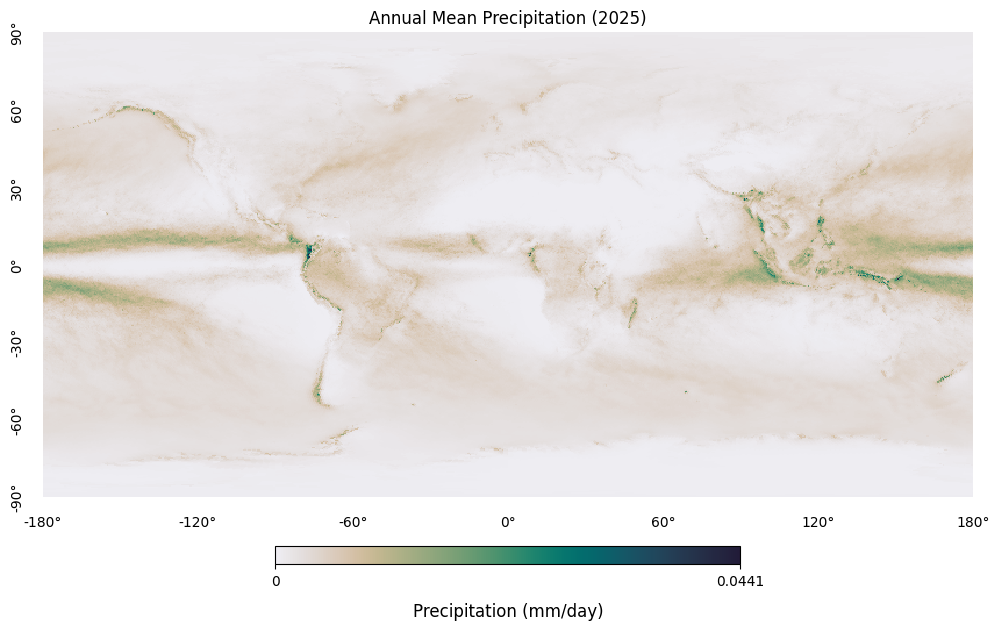

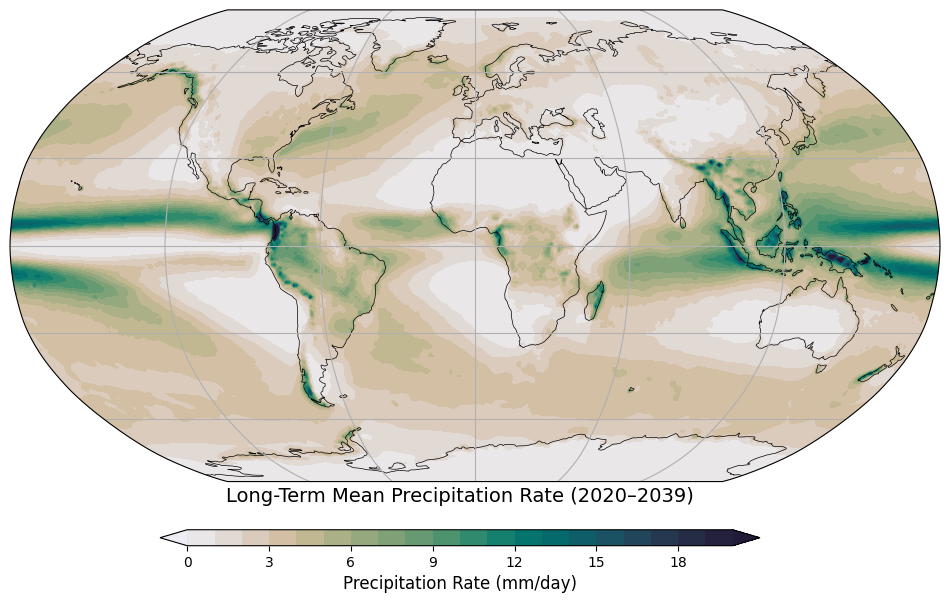

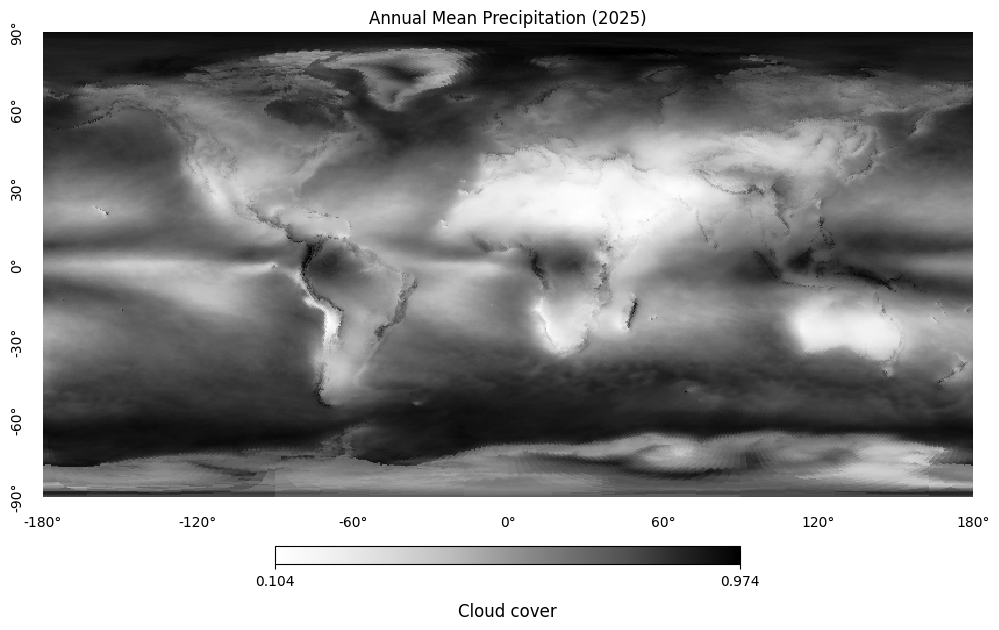

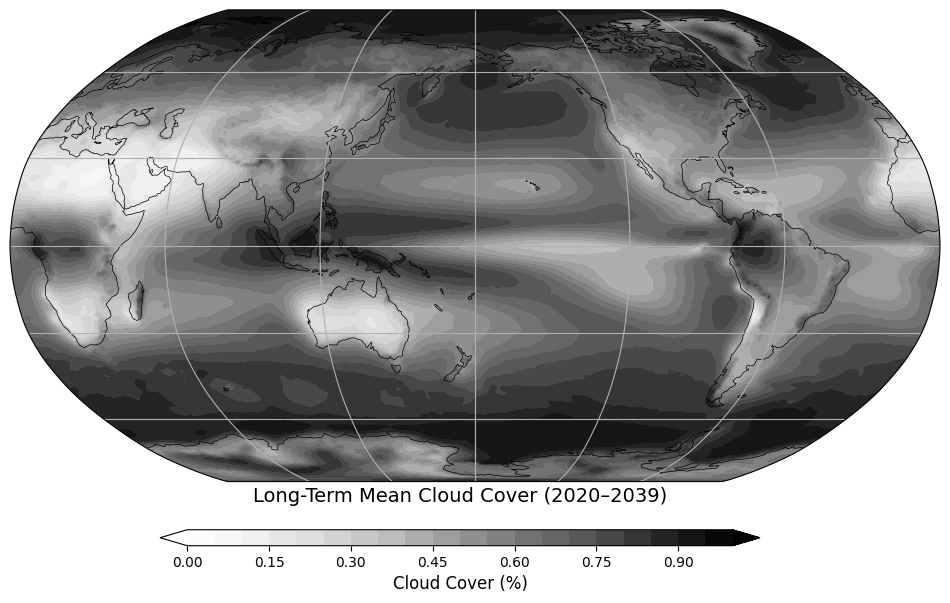

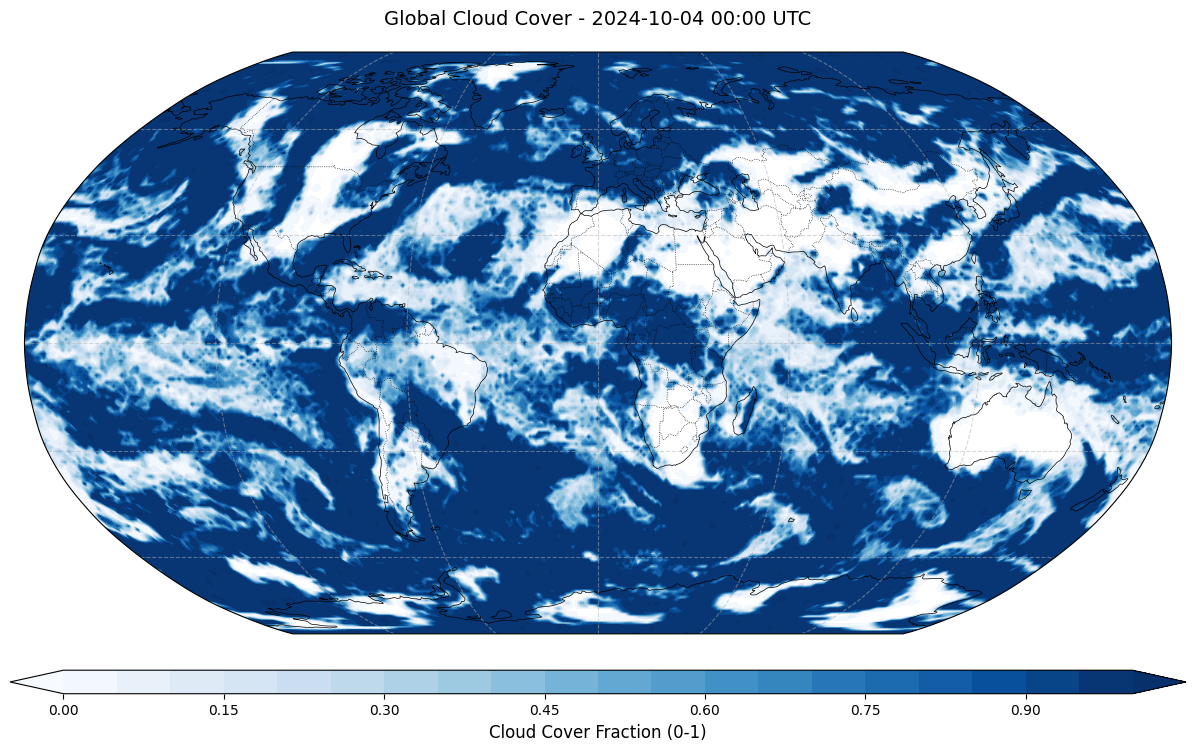

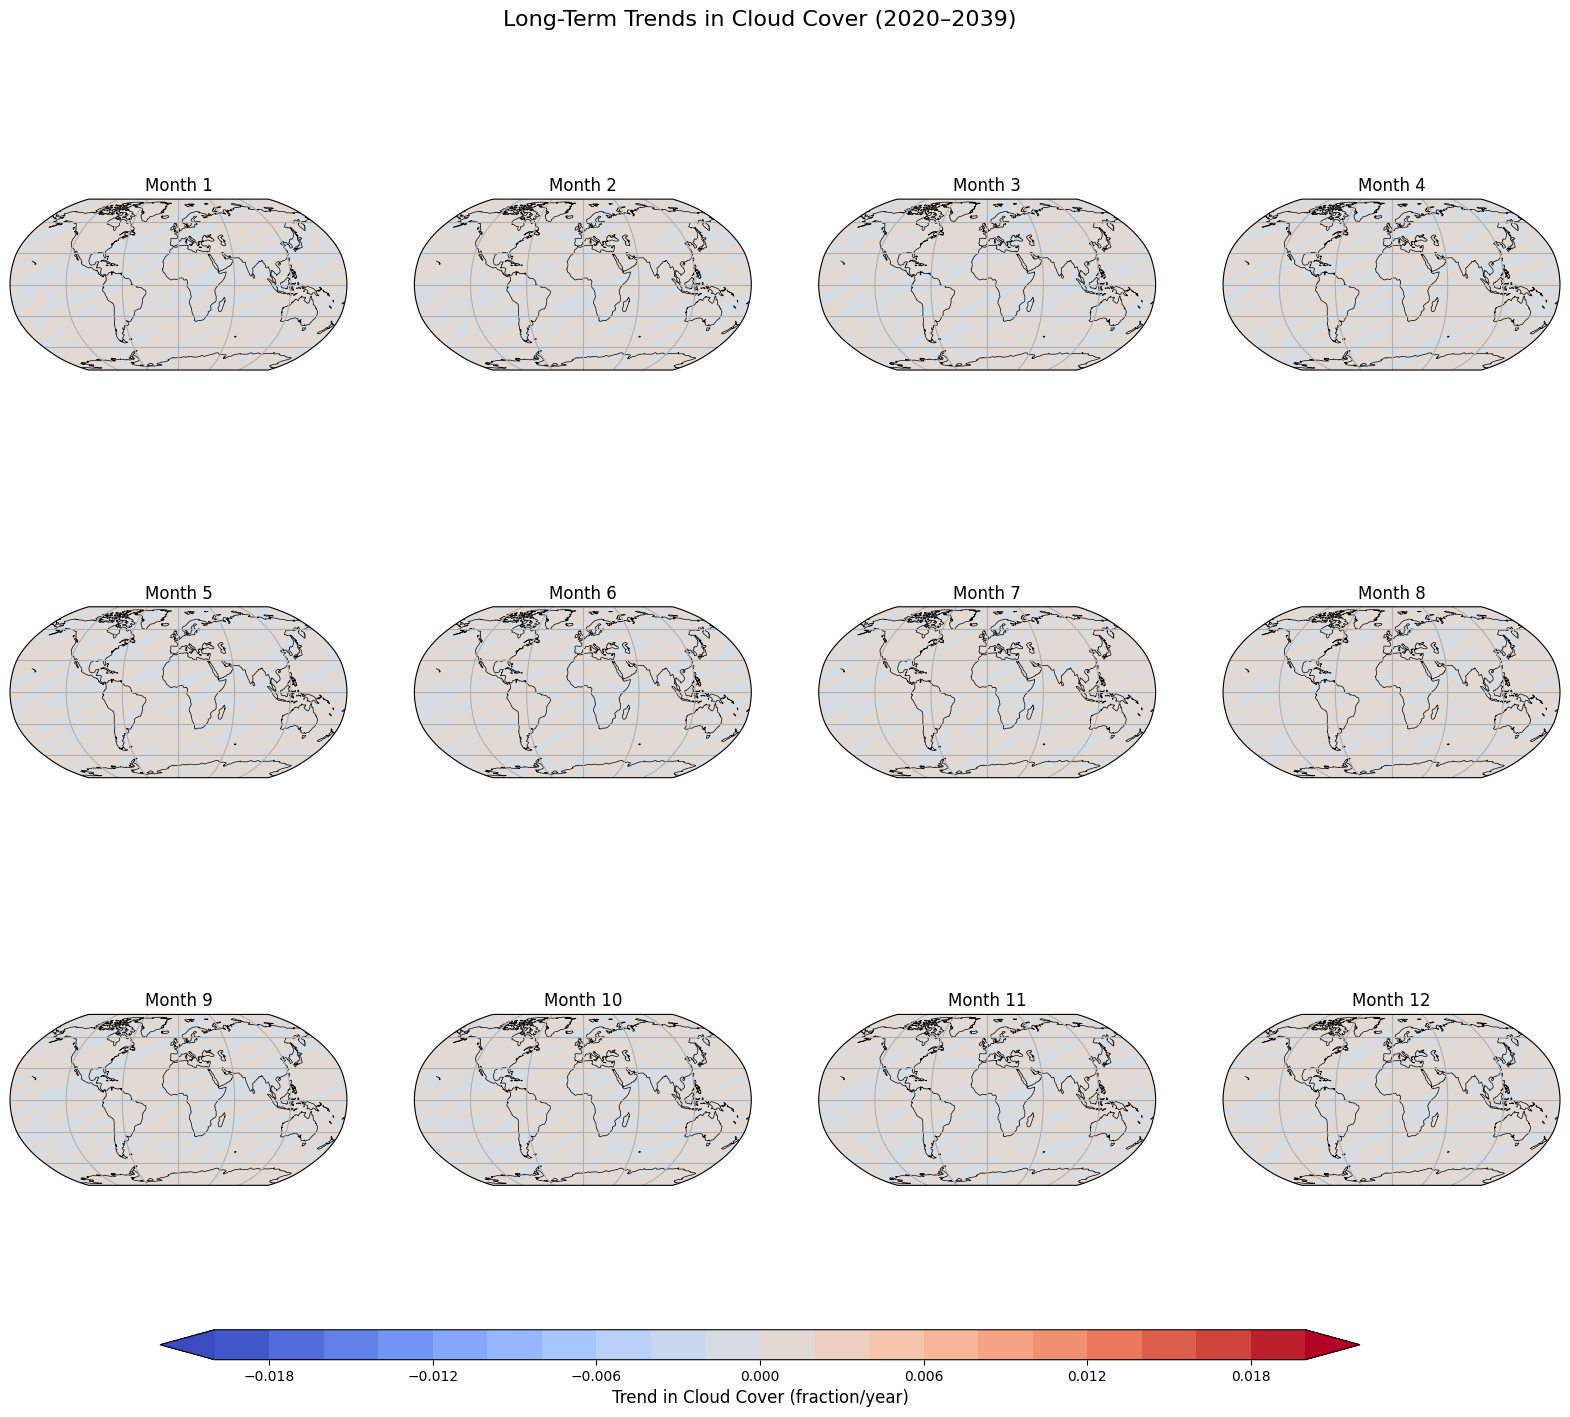